In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080208
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] course-env
[学号] 20244080208
[机器指纹] 2d0321b280a8536f
[RUN_ID] 20244080208-2d0321b280a8536f


## 实验1：NumPy数组、数据类型与索引

In [2]:
int_arr = np.array([1, 2, 3, 4])
float_arr = np.array([1.0, 2.5, 3.5])
bool_arr = np.array([True, False, True])

for name, arr in [("整数", int_arr), ("浮点", float_arr), ("布尔", bool_arr)]:
    print(f"{name}数组: {arr}")
    print(f"  dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

整数数组: [1 2 3 4]
  dtype=int64, shape=(4,), ndim=1
浮点数组: [1.  2.5 3.5]
  dtype=float64, shape=(3,), ndim=1
布尔数组: [ True False  True]
  dtype=bool, shape=(3,), ndim=1


NumPy 数组要求所有元素具有**同一种数据类型**（dtype），因此内存连续、运算向量化；而 Python 列表可以混合存放任意对象，每个元素是独立对象，运算需逐个循环。上例中整数数组 dtype 为 int64，浮点为 float64，布尔为 bool。

In [3]:
a = np.arange(12)
print("一维:", a)

a_3x4 = a.reshape(3, 4)
print("\n形状(3,4):\n", a_3x4)

a_2x3x2 = a.reshape(2, 3, 2)
print("\n形状(2,3,2):\n", a_2x3x2)

一维: [ 0  1  2  3  4  5  6  7  8  9 10 11]

形状(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


改变形状时，**新形状各维度乘积必须等于原数组元素总数**。原数组有 12 个元素，3×4=12、2×3×2=12 均满足；若 reshape 成 (3,5) 会因 15≠12 报错。

In [4]:
arr = np.arange(12).reshape(3, 4)
print("原数组:\n", arr)

row2 = arr[1]
print("\n第2行:", row2, "shape:", row2.shape)

cols1to3 = arr[:, 0:3]
print("\n第1至第3列:\n", cols1to3, "shape:", cols1to3.shape)

gt6 = arr[arr > 6]
print("\n大于6的元素:", gt6, "shape:", gt6.shape)

原数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第2行: [4 5 6 7] shape: (4,)

第1至第3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)

大于6的元素: [ 7  8  9 10 11] shape: (5,)


In [5]:
x = np.arange(10)

cond_or = (x < 2) | (x > 7)
print("小于2或大于7:", x[cond_or])
print("用 logical_or 验证:", x[np.logical_or(x < 2, x > 7)])

cond_and = (x > 3) & (x < 7)
print("大于3且小于7:", x[cond_and])
print("用 logical_and 验证:", x[np.logical_and(x > 3, x < 7)])

小于2或大于7: [0 1 8 9]
用 logical_or 验证: [0 1 8 9]
大于3且小于7: [4 5 6]
用 logical_and 验证: [4 5 6]


组合多个条件时**每个条件都要用括号括起来**，因为 `&`、`|` 的优先级高于比较运算符。`np.logical_or()` / `np.logical_and()` 是等价的函数写法。

In [6]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A * B (逐元素):\n", A * B)
print("np.multiply(A,B):\n", np.multiply(A, B))
print("\nA @ B (矩阵乘法):\n", A @ B)
print("np.matmul(A,B):\n", np.matmul(A, B))

A * B (逐元素):
 [[ 5 12]
 [21 32]]
np.multiply(A,B):
 [[ 5 12]
 [21 32]]

A @ B (矩阵乘法):
 [[19 22]
 [43 50]]
np.matmul(A,B):
 [[19 22]
 [43 50]]


`*` 与 `np.multiply()` 是**逐元素相乘**，对应位置元素相乘，要求形状一致（或可广播）；`@` 与 `np.matmul()` 是**矩阵乘法**，按线性代数规则行乘列，要求前者的列数等于后者的行数。二者结果完全不同。

## 实验2：随机抽样、统计与缺失值

In [7]:
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", scores.max() - scores.min())

样本数: 1000
最小值: 37.58732659930927
最大值: 100.0
均值: 70.18400443523215
标准差: 9.755086339034765
极差: 62.41267340069073


In [8]:
np.random.seed(42)
pool = np.arange(1, 11)

uniform_sample = np.random.choice(pool, size=5, replace=False)
print("均匀不放回抽样:", uniform_sample)

weights = pool / pool.sum()
weighted_sample = np.random.choice(pool, size=5, replace=False, p=weights)
print("按整数大小成比例加权不放回抽样:", weighted_sample)

均匀不放回抽样: [9 2 6 1 8]
按整数大小成比例加权不放回抽样: [ 4  3 10  8  9]


均匀抽样每个整数被抽中的概率相同；加权抽样用 `p=` 指定概率向量（需归一化，和为 1），这里权重与整数大小成正比，因此大数更容易被抽中。`replace=False` 表示不放回。

In [9]:
np.random.seed(42)
orig1 = np.arange(10)
print("permutation 前原数组:", orig1)
perm = np.random.permutation(orig1)
print("permutation 结果:", perm)
print("permutation 后原数组:", orig1)

np.random.seed(42)
orig2 = np.arange(10)
print("\nshuffle 前原数组:", orig2)
np.random.shuffle(orig2)
print("shuffle 后原数组:", orig2)

permutation 前原数组: [0 1 2 3 4 5 6 7 8 9]
permutation 结果: [8 1 5 0 7 2 9 4 3 6]
permutation 后原数组: [0 1 2 3 4 5 6 7 8 9]

shuffle 前原数组: [0 1 2 3 4 5 6 7 8 9]
shuffle 后原数组: [8 1 5 0 7 2 9 4 3 6]


`np.random.permutation()` 返回打乱后的**新数组**，原数组不变；`np.random.shuffle()` **原地打乱**，原数组被修改且无返回值。

In [10]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan

print("普通均值:", np.mean(scores_nan))
print("忽略缺失值均值:", np.nanmean(scores_nan))
print("缺失值个数:", np.isnan(scores_nan).sum())

普通均值: nan
忽略缺失值均值: 70.19620743160239
缺失值个数: 3


`np.nan` 参与普通统计函数（如 `np.mean`）时会使结果为 `nan`，因为 nan 与任何数运算都得 nan。应使用 `np.nanmean` 等忽略缺失值的函数，或用 `np.isnan` 统计缺失个数。

In [11]:
score_df = pd.DataFrame({
    "Index": np.arange(len(scores_nan)),
    "Score": scores_nan
})
print(score_df.head())
print("缺失值个数:", score_df["Score"].isna().sum())

   Index      Score
0      0  74.967142
1      1  68.617357
2      2  76.476885
3      3  85.230299
4      4  67.658466
缺失值个数: 3


## 实验3：SciPy 数值计算与 Matplotlib 可视化

In [12]:
from scipy.linalg import solve

A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = solve(A, b)
print("解:", sol)

print("NumPy 代入验证 A@sol:", A @ sol)
print("是否等于 b:", np.allclose(A @ sol, b))

解: [2. 3.]
NumPy 代入验证 A@sol: [9. 8.]
是否等于 b: True


In [13]:
from scipy.optimize import root

f = lambda x: x**2 - 2

res_pos = root(f, x0=1.0)
print("正根 成功:", res_pos.success, "解:", res_pos.x, "函数值:", f(res_pos.x))

res_neg = root(f, x0=-1.0)
print("负根 成功:", res_neg.success, "解:", res_neg.x, "函数值:", f(res_neg.x))

正根 成功: True 解: [1.41421356] 函数值: [-8.8817842e-16]
负根 成功: True 解: [-1.41421356] 函数值: [-8.8817842e-16]


In [14]:
from scipy.optimize import minimize

f2 = lambda x: x**2 + x + 2
res_min = minimize(f2, x0=0.0)
print("极小点:", res_min.x, "函数值:", res_min.fun)

# 解析结果：x = -0.5, f = 1.75
print("解析极小点: -0.5, 解析最小值: 1.75")

极小点: [-0.50000001] 函数值: 1.75
解析极小点: -0.5, 解析最小值: 1.75


In [15]:
from scipy.stats import ttest_ind

np.random.seed(42)
g1 = np.random.normal(loc=0, scale=1, size=100)
g2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_val = ttest_ind(g1, g2)
print("t 统计量:", t_stat)
print("p 值:", p_val)
if p_val < 0.05:
    print("p < 0.05，拒绝原假设，两组均值存在显著差异")
else:
    print("p >= 0.05，不能拒绝原假设")

t 统计量: -8.55145994324873
p 值: 3.292961428703696e-15
p < 0.05，拒绝原假设，两组均值存在显著差异


Matplotlib is building the font cache; this may take a moment.
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26377 (\N{CJK UNIFIED IDEOGRAPH-6709}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25928 (\N{CJK UNIFIED IDEOGRAPH-6548}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning

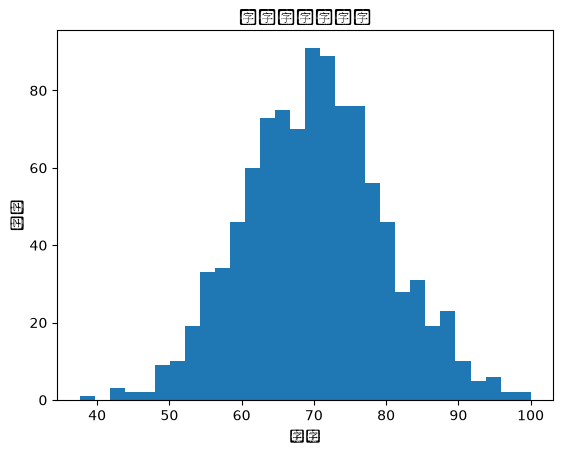

d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26377 (\N{CJK UNIFIED IDEOGRAPH-6709}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25928 (\N{CJK UNIFIED IDEOGRAPH-6548}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from fon

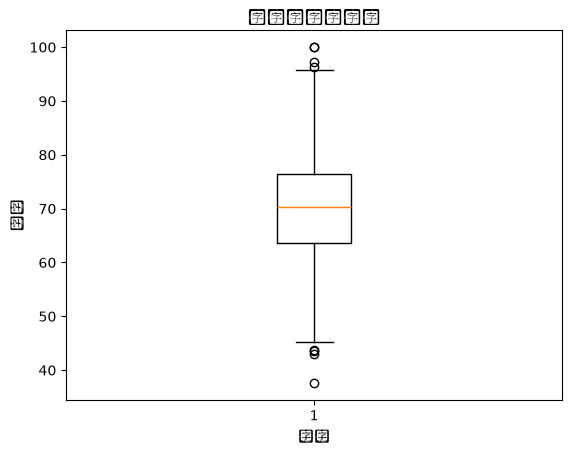

d:\Anaconda\envs\course-env\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25240 (\N{CJK UNIFIED IDEOGRAPH-6298}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


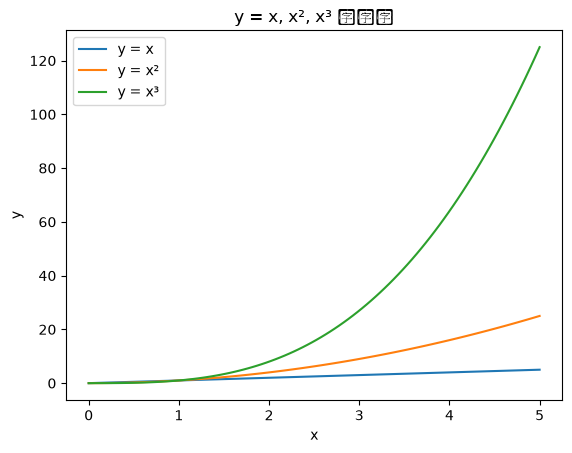

In [16]:
import matplotlib.pyplot as plt

valid_scores = scores_nan[~np.isnan(scores_nan)]

# 直方图
plt.figure()
plt.hist(valid_scores, bins=30)
plt.title("有效成绩直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.show()

# 箱线图
plt.figure()
plt.boxplot(valid_scores)
plt.title("有效成绩箱线图")
plt.xlabel("成绩")
plt.ylabel("数值")
plt.show()

# 折线图
x = np.linspace(0, 5, 100)
plt.figure()
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x²")
plt.plot(x, x**3, label="y = x³")
plt.title("y = x, x², x³ 折线图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

In [17]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前3行:\n", df.head(3))
print("\n基本统计信息:\n", df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
print("loc 读取 Carol:\n", df.loc["Carol"])
print("\niloc 读取 Carol（第3行，位置2）:\n", df.iloc[2])

print("\n平均分不低于80的学生:\n", df[df["Average"] >= 80])

loc 读取 Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc 读取 Carol（第3行，位置2）:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于80的学生:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
print("三科列均值 mean(axis=0):\n", df[["Math", "English", "Python"]].mean(axis=0))
print("\n每名学生行均值 mean(axis=1):\n", df[["Math", "English", "Python"]].mean(axis=1))

三科列均值 mean(axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生行均值 mean(axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
df["MaxScore"] = df[["Math", "English", "Python"]].apply(np.max, axis=1)
print("每名学生三科最高分:\n", df["MaxScore"])

agg_res = df[["Math", "English", "Python"]].agg(["min", "mean", "max"])
print("\n每科 min/mean/max:\n", agg_res)

df["Math_rank"] = df["Math"].rank(ascending=False)
print("\nMath 排名:\n", df["Math_rank"])

每名学生三科最高分:
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: MaxScore, dtype: int64

每科 min/mean/max:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Math 排名:
 Name
Alice    2.0
Bob      5.0
Carol    1.0
David    6.0
Eva      4.0
Frank    3.0
Name: Math_rank, dtype: float64


In [21]:
group_stat = df.groupby("Group").agg(
    Count=("Name", "count") if "Name" in df.columns else ("Math", "count"),
    Math_mean=("Math", "mean"),
    English_mean=("English", "mean"),
    Python_mean=("Python", "mean"),
)
print("按 Group 分组统计:\n", group_stat)

df["Group_Python_mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组内 Python 平均分列:\n", df[["Group", "Python", "Group_Python_mean"]])

按 Group 分组统计:
        Count  Math_mean  English_mean  Python_mean
Group                                             
A          3  79.666667     83.333333    87.000000
B          3  80.000000     78.333333    80.333333

增加组内 Python 平均分列:
       Group  Python  Group_Python_mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [22]:
group_py_mean = df.groupby("Group")["Python"].mean()
kept_groups = group_py_mean[group_py_mean >= 80].index.tolist()
print("保留的组:", kept_groups)

kept_df = df[df["Group"].isin(kept_groups)]
print("\n保留组的学生:\n", kept_df)

# 也可用 groupby.filter 写法
print("\n用 filter 写法:\n", df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80))

保留的组: ['A', 'B']

保留组的学生:
       Group  Math  English  Python  Total    Average  MaxScore  Math_rank  \
Name                                                                        
Alice     A    88       90      95    273  91.000000        95        2.0   
Bob       A    72       68      80    220  73.333333        80        5.0   
Carol     B    91       85      89    265  88.333333        91        1.0   
David     B    65       73      70    208  69.333333        73        6.0   
Eva       A    79       92      86    257  85.666667        92        4.0   
Frank     B    84       77      82    243  81.000000        84        3.0   

       Group_Python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  

用 filter 写法:
       Group  Math  English  Python  Total    Average  MaxScore  Math_rank  \
Name                                            

In [23]:
cov_mat = df[["Math", "English", "Python"]].cov()
corr_mat = df[["Math", "English", "Python"]].corr()

print("协方差矩阵:\n", cov_mat)
print("\n皮尔森相关系数矩阵:\n", corr_mat)

协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔森相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


以 Math 与 English 为例：协方差为正，说明两科成绩变化方向一致（一科高于均值时另一科也倾向高于均值）；相关系数绝对值越接近 1，线性关系越强，接近 0 则线性关系弱。协方差大小受量纲影响，相关系数已归一化到 [-1, 1]，更便于比较强弱。